## **News Classification Using Machine Learning**

In [ ]:
# IMPORT LIBRARIES

import json #For reading data in JSON format
import string #To obtain a list of punctuation marks.
import warnings #It helps in controlling Python warning messages.

import numpy as np #for numerical calculations
import pandas as pd #for manipulating tabular, real-world datasets
import matplotlib.pyplot as plt #Graph and chart

import nltk #Natural Language Processing (NLP)
from nltk.corpus import stopwords #A list of common English stopwords is used.

from google.colab import drive

from sklearn.model_selection import train_test_split #Divides the data into training and testing sets.
from sklearn.preprocessing import LabelEncoder #Converts category names into numbers.

from sklearn.feature_extraction.text import TfidfVectorizer #Converts text into numerical features.

from sklearn.linear_model import LogisticRegression #Learns to determine which category a piece of news belongs to.
from sklearn.naive_bayes import MultinomialNB #Multinomial Naive Bayes:using the presence and probability of words.
from sklearn.svm import LinearSVC #Linear Support Vector Machine : Learns a decision boundary.

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

nltk.download("stopwords")

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# LOAD DATASET

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/NewsClassificationDataSet.csv"

data = []

with open(file_path, 'r', encoding='utf-8') as file:

    for line in file:

        row = json.loads(line)

        text = row['content']

        label = row['annotation']['label'][0]

        data.append([text, label])


df = pd.DataFrame(
    data,
    columns=['text', 'label']
)

print("Dataset Shape:", df.shape) # Total rows, columns

df.head() #first 5 row show

Mounted at /content/drive
Dataset Shape: (7600, 2)


,text,label
0,Unions representing workers at Turner Newall...,Business
1,"SPACE.com - TORONTO, Canada -- A second\team o...",SciTech
2,AP - A company founded by a chemistry research...,SciTech
3,AP - It's barely dawn when Mike Fitzpatrick st...,SciTech
4,AP - Southern California's smog-fighting agenc...,SciTech


In [ ]:
# DATASET INFORMATION

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['label'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7600 entries, 0 to 7599
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7600 non-null   object
 1   label   7600 non-null   object
dtypes: object(2)
memory usage: 118.9+ KB
None

Missing Values:
text     0
label    0
dtype: int64

Class Distribution:
label
Business    1900
SciTech     1900
Sports      1900
World       1900
Name: count, dtype: int64


In [ ]:
# HANDLE MISSING VALUES

df = df.dropna( #Missing value removed
    subset=['text', 'label']
)

df = df.reset_index( # new index set
    drop=True
)

print("Dataset Shape After Cleaning:", df.shape) #Total row and column

Dataset Shape After Cleaning: (7600, 2)


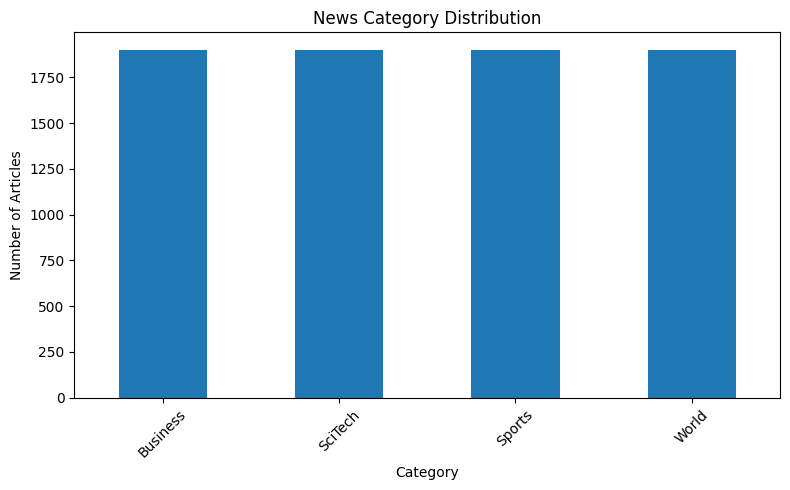

In [ ]:
# CLASS DISTRIBUTION FIGURE

plt.figure(figsize=(8, 5))

df['label'].value_counts().plot(
    kind='bar'
)

plt.title("News Category Distribution")

plt.xlabel("Category")

plt.ylabel("Number of Articles")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [ ]:
# TEXT PREPROCESSING

stop_words = set( #clean the stopwords
    stopwords.words('english')
)

def clean_text(text): #create a function

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    text = ''.join(
        char for char in text
        if char not in string.punctuation
    )

    # Split words
    words = text.split()

    # list comprehension with stopwords
    words = [
        word
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


df['clean_text'] = df['text'].apply(
    clean_text
)


print("Original Text:")
print(df['text'].iloc[0])

print("\nCleaned Text:")
print(df['clean_text'].iloc[0])

Original Text:
Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.

Cleaned Text:
unions representing workers turner newall say disappointed talks stricken parent firm federal mogul


In [ ]:
# LABEL ENCODING

encoder = LabelEncoder()

df['encoded_label'] = encoder.fit_transform(
    df['label']
)

print("News Categories:")

for i, category in enumerate(encoder.classes_):

    print(i, "=", category)

News Categories:
0 = Business
1 = SciTech
2 = Sports
3 = World


In [ ]:
# TRAIN TEST SPLIT

X = df['clean_text']

y = df['encoded_label']


X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("Training Data:", len(X_train))

print("Testing Data :", len(X_test))

Training Data: 6080
Testing Data : 1520


In [ ]:
# TF-IDF VECTORIZATION
#TF-IDF means Term Frequency–Inverse Document Frequency
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(
    X_train
)

X_test_tfidf = tfidf.transform(
    X_test
)

print("Training TF-IDF Shape:")
print(X_train_tfidf.shape)


print("\nTesting TF-IDF Shape:")
print(X_test_tfidf.shape)

Training TF-IDF Shape:
(6080, 10000)

Testing TF-IDF Shape:
(1520, 10000)


Accuracy=
(Correct Predictions/Total Predictions)
*100


In [ ]:
# LOGISTIC REGRESSION

logistic_model = LogisticRegression( #Model create
    max_iter=1000
)

logistic_model.fit( #Model train
    X_train_tfidf,
    y_train
)

logistic_pred = logistic_model.predict( #Prediction
    X_test_tfidf
)

logistic_accuracy = accuracy_score( #Accuracy count
    y_test,
    logistic_pred
)

print( "Logistic Regression Accuracy:", f"{logistic_accuracy * 100:.2f}%"
)

Logistic Regression Accuracy: 85.92%


In [ ]:
# MULTINOMIAL NAIVE BAYES

nb_model = MultinomialNB() #Model create

nb_model.fit( #Model train
    X_train_tfidf,
    y_train
)

nb_pred = nb_model.predict( #Prediction
    X_test_tfidf
)

nb_accuracy = accuracy_score( #Accuracy count
    y_test,
    nb_pred
)


print(
    "Naive Bayes Accuracy:",
    f"{nb_accuracy * 100:.2f}%"
)

Naive Bayes Accuracy: 86.97%


In [ ]:
# LINEAR SVM
svm_model = LinearSVC() #Model create

svm_model.fit( #Model train
    X_train_tfidf,
    y_train
)

svm_pred = svm_model.predict( #Prediction
    X_test_tfidf
)

svm_accuracy = accuracy_score( #Accuracy count
    y_test,
    svm_pred
)


print(
    "Linear SVM Accuracy:",
    f"{svm_accuracy * 100:.2f}%"
)

Linear SVM Accuracy: 85.13%


In [ ]:
# MODEL COMPARISON
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'Linear SVM'
    ],

    'Accuracy': [
        logistic_accuracy,
        nb_accuracy,
        svm_accuracy
    ]
})

results['Accuracy (%)'] = (
    results['Accuracy'] * 100
)

print(results)

                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.859211     85.921053
1          Naive Bayes  0.869737     86.973684
2           Linear SVM  0.851316     85.131579


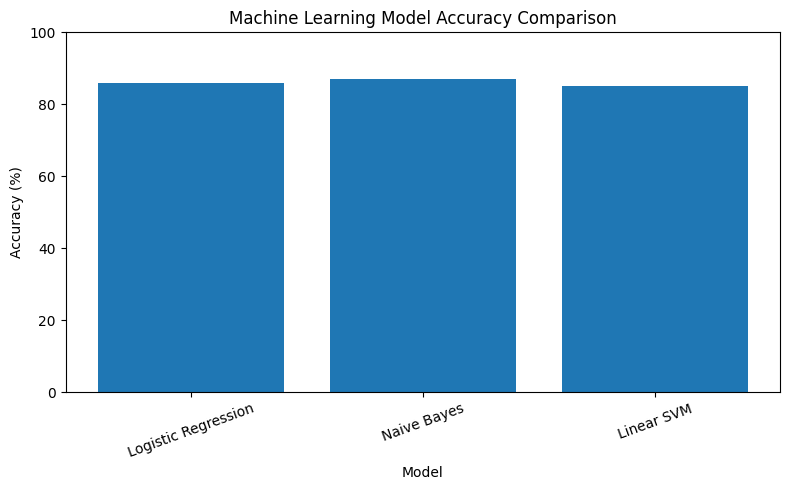

In [ ]:
# ACCURACY COMPARISON
plt.figure(figsize=(8, 5))
plt.bar(
    results['Model'],
    results['Accuracy (%)']
)

plt.title(
    "Machine Learning Model Accuracy Comparison"
)

plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# BEST MODEL

best_index = results['Accuracy'].idxmax()
best_model_name = results.loc[
    best_index,
    'Model'
]

best_accuracy = results.loc[
    best_index,
    'Accuracy (%)'
]


print("Best Model:", best_model_name)
print(
    f"Best Accuracy: {best_accuracy:.2f}%"
)

Best Model: Naive Bayes
Best Accuracy: 86.97%


**Precision:** Out of all the items the model assigned to a particular category, what proportion is actually correct?

**Recall:** Out of all the items that truly belong to a particular category, how many was the model able to correctly identify?

**F1-score:** A balanced score between Precision and Recall.

**Support:** The actual number of items belonging to that category in the test data.

In [ ]:
# LOGISTIC REGRESSION REPORT

print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

    Business       0.85      0.79      0.82       380
     SciTech       0.81      0.84      0.82       380
      Sports       0.90      0.96      0.93       380
       World       0.88      0.85      0.86       380

    accuracy                           0.86      1520
   macro avg       0.86      0.86      0.86      1520
weighted avg       0.86      0.86      0.86      1520



In [ ]:
# NAIVE BAYES REPORT
print(
    classification_report(
        y_test,
        nb_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

    Business       0.83      0.82      0.82       380
     SciTech       0.84      0.84      0.84       380
      Sports       0.91      0.96      0.94       380
       World       0.89      0.86      0.88       380

    accuracy                           0.87      1520
   macro avg       0.87      0.87      0.87      1520
weighted avg       0.87      0.87      0.87      1520



In [ ]:
# SVM CLASSIFICATION REPORT
print(
    classification_report(
        y_test,
        svm_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

    Business       0.83      0.79      0.81       380
     SciTech       0.80      0.81      0.80       380
      Sports       0.91      0.96      0.93       380
       World       0.87      0.84      0.86       380

    accuracy                           0.85      1520
   macro avg       0.85      0.85      0.85      1520
weighted avg       0.85      0.85      0.85      1520



Accuracy gives overall correctness, while precision, recall and F1-score help evaluate classification performance for individual classes.

CONFUSION MATRIX: Seeing the Total correct and incorrect predictions

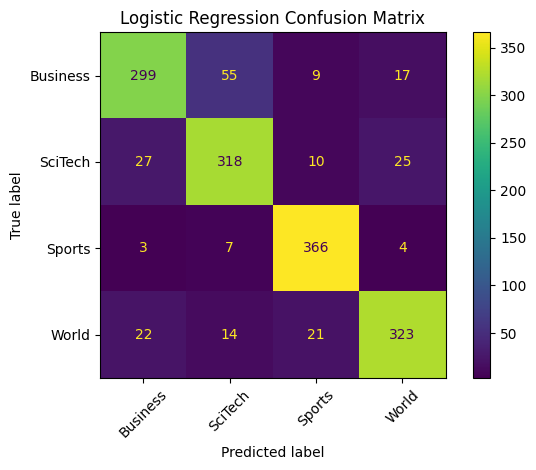

In [ ]:
# CONFUSION MATRIX (LOGISTIC REGRESSION)
cm_logistic = confusion_matrix(
    y_test,
    logistic_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=encoder.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.tight_layout()
plt.show()

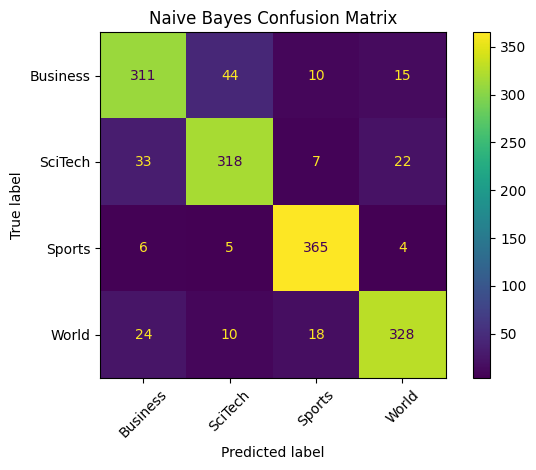

In [ ]:
# CONFUSION MATRIX (NAIVE BAYES)
cm_nb = confusion_matrix(
    y_test,
    nb_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=encoder.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Naive Bayes Confusion Matrix"
)
plt.tight_layout()
plt.show()

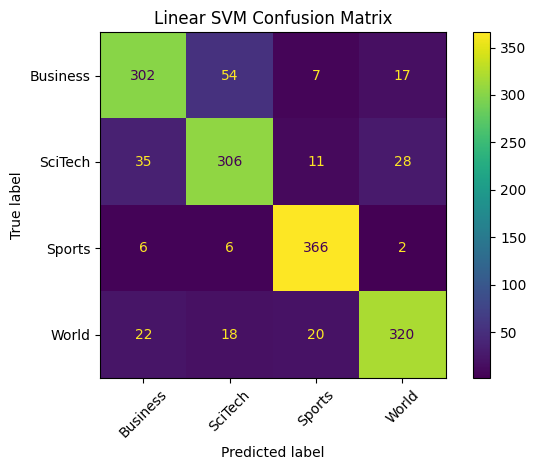

In [ ]:
# CONFUSION MATRIX (LINEAR SVM)

cm_svm = confusion_matrix(
    y_test,
    svm_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=encoder.classes_
)

disp.plot(
    xticks_rotation=45
)

plt.title(
    "Linear SVM Confusion Matrix"
)
plt.tight_layout()
plt.show()

In [ ]:
# CUSTOM NEWS PREDICTION

models = {
    'Logistic Regression': logistic_model,
    'Naive Bayes': nb_model,
    'Linear SVM': svm_model
}

best_model = models[
    best_model_name
]

def predict_news(news):

    # Clean news
    cleaned_news = clean_text(news)

    # TF-IDF transformation
    news_tfidf = tfidf.transform(
        [cleaned_news]
    )

    # Prediction
    prediction = best_model.predict(
        news_tfidf
    )

    # Convert number to category
    category = encoder.inverse_transform(
        prediction
    )[0]

    print("News:")
    print(news)

    print("\nPredicted Category:")
    print(category)

    print("\nModel Used:")
    print(best_model_name)

In [ ]:
# TEST 1
predict_news(
    "Scientists developed a new artificial intelligence system for healthcare."
)

News:
Scientists developed a new artificial intelligence system for healthcare.

Predicted Category:
SciTech

Model Used:
Naive Bayes


In [ ]:
# TEST 2
predict_news(
    "The football team won the world championship after a dramatic final."
)

News:
The football team won the world championship after a dramatic final.

Predicted Category:
Sports

Model Used:
Naive Bayes


In [ ]:
#  TEST 3
predict_news(
    "Apple announced strong quarterly earnings and increased revenue."
)

News:
Apple announced strong quarterly earnings and increased revenue.

Predicted Category:
Business

Model Used:
Naive Bayes


In [ ]:
# TEST 4
predict_news(
    "World leaders met to discuss international peace and security."
)

News:
World leaders met to discuss international peace and security.

Predicted Category:
World

Model Used:
Naive Bayes


In [ ]:
# 27. FINAL SUMMARY
print("NEWS CLASSIFICATION PROJECT RESULTS")
print("=" * 50)

for index, row in results.iterrows():
    print(
        f"{row['Model']}: "
        f"{row['Accuracy (%)']:.2f}%"
    )

print("-" * 50)
print(
    f"Best Model: {best_model_name}"
)

print(
    f"Best Accuracy: {best_accuracy:.2f}%"
)


NEWS CLASSIFICATION PROJECT RESULTS
Logistic Regression: 85.92%
Naive Bayes: 86.97%
Linear SVM: 85.13%
--------------------------------------------------
Best Model: Naive Bayes
Best Accuracy: 86.97%
